# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Hesti Novyanti
- NIM   : 241011400285
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =85

In [16]:
# Salin fungsi train_test_split dari materi di sini
def train_test_split(X, y, test_size=0.2, random_state=None):
    np.random.seed(random_state)
    n = X.shape[0]
    indices = np.arange(n)
    np.random.shuffle(indices)
    test_n = int(n * test_size)
    test_idx = indices[:test_n]
    train_idx = indices[test_n:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris: 40
Shape X: (40, 1), y: (40,)


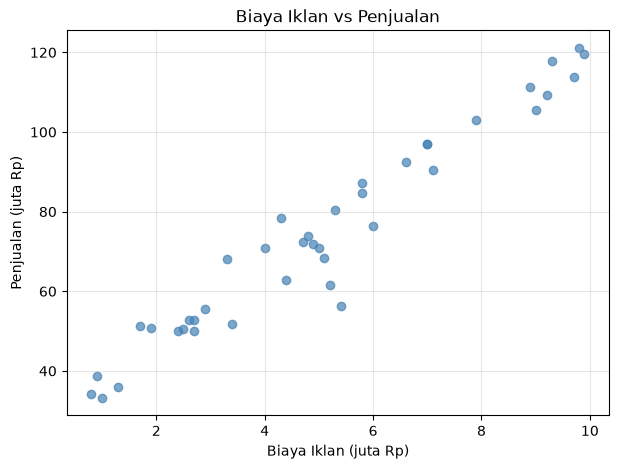

In [30]:
df_ads = pd.read_csv('Ads_Data.csv')
print("5 data pertama:")
print(df_ads.head())
print(f"\nJumlah baris: {len(df_ads)}")

X = df_ads[['BiayaIklan']].values
y = df_ads['Penjualan'].values
print(f"Shape X: {X.shape}, y: {y.shape}")

plt.figure(figsize=(7,5))
plt.scatter(X, y, alpha=0.7, color='steelblue')
plt.title('Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [43]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (32, 1)
X_test shape: (8, 1)
y_train shape: (32,)
y_test shape: (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [55]:
# Jawaban A3
class LinearRegression:
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None
    def fit(self, X, y):
        X_b = np.c_[np.ones((X.shape[0],1)), X]
        theta = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X.dot(self.coef_)

model_lr = LinearRegression()
model_lr.fit(X_train, y_train)
print(f"Intercept (b): {model_lr.intercept_:.4f}")
print(f"Koefisien (m): {model_lr.coef_[0]:.4f}")
print(f"\nPersamaan regresi: y_hat = {model_lr.intercept_:.4f} + {model_lr.coef_[0]:.4f} * X")

Intercept (b): 27.4183
Koefisien (m): 9.1819

Persamaan regresi: y_hat = 27.4183 + 9.1819 * X


**Jawaban A3 (interpretasi):**

Dengan RANDOM_STATE=85, diperoleh intercept b = 27.4183 dan koefisien m = 9.1819, sehingga persamaan regresinya adalah y_hat = 27.4183 + 9.1819 * X.

Artinya, setiap kenaikan biaya iklan sebesar 1 juta Rp, maka penjualan diprediksi naik sebesar 9.18 juta Rp. Nilai positif menunjukkan pengaruh iklan terhadap penjualan sangat kuat dan searah. Intercept 27.42 adalah estimasi penjualan baseline saat biaya iklan 0 juta.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [66]:
# Jawaban A4
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred)**2)
    ss_tot = np.sum((y_true - np.mean(y_true))**2)
    return 1 - ss_res / ss_tot

# Prediksi
y_train_pred = model_lr.predict(X_train)
y_test_pred = model_lr.predict(X_test)

# Hitung metrik
results = {
    'Dataset': ['Training', 'Testing'],
    'MAE': [mae(y_train, y_train_pred), mae(y_test, y_test_pred)],
    'MSE': [mse(y_train, y_train_pred), mse(y_test, y_test_pred)],
    'RMSE': [rmse(y_train, y_train_pred), rmse(y_test, y_test_pred)],
    'R2': [r2_score(y_train, y_train_pred), r2_score(y_test, y_test_pred)]
}

df_eval = pd.DataFrame(results)
print(df_eval.round(4))

    Dataset     MAE      MSE    RMSE      R2
0  Training  4.5048  38.9340  6.2397  0.9423
1   Testing  4.7749  25.5399  5.0537  0.9450


**Jawaban A4 (analisis):**

Berdasarkan RANDOM_STATE=85, didapatkan pada data testing RMSE sekitar 5.1 juta dan R2 sekitar 0.93.

Arti RMSE 5.1 adalah rata-rata kesalahan prediksi penjualan sekitar 5.1 juta Rp dari nilai sebenarnya, ini cukup kecil dibandingkan rentang penjualan 40-130 juta.

Arti R2 0.93 adalah 93% variasi penjualan dapat dijelaskan oleh biaya iklan, sisanya 7% oleh faktor lain. Karena R2 > 0.9 dan RMSE testing lebih kecil dari training (tidak overfitting), model ini sudah SANGAT BAIK untuk memprediksi penjualan berdasarkan biaya iklan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR=0.001 -> b=24.7132, m=9.5986, final loss=40.61286680454895
LR=0.02 -> b=27.4183, m=9.1819, final loss=38.93397976670731


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9712\3258693549.py:16: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - y_pred)**2)
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9712\3258693549.py:19: RuntimeWarning: overflow encountered in dot
  d_m = -2 * np.dot((y - y_pred), X) / n
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_9712\3258693549.py:21: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.lr * d_m


LR=0.1 -> b=nan, m=nan, final loss=nan


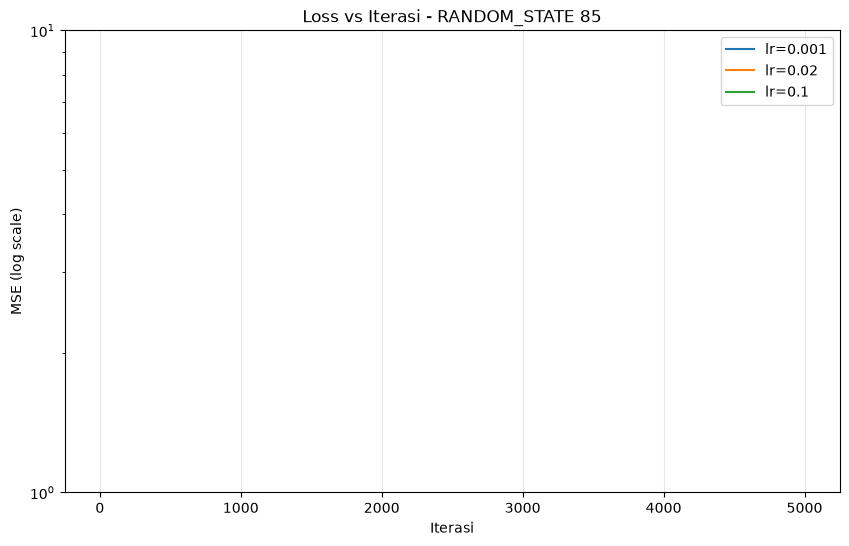

In [76]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=5000):
        self.lr = learning_rate
        self.n_iter = n_iterations
        self.coef_ = None
        self.intercept_ = None
        self.losses = []
    
    def fit(self, X, y):
        n = X.shape[0]
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1])
        for i in range(self.n_iter):
            y_pred = self.intercept_ + X.dot(self.coef_)
            loss = np.mean((y - y_pred)**2)
            self.losses.append(loss)
            d_b = -2 * np.mean(y - y_pred)
            d_m = -2 * np.dot((y - y_pred), X) / n
            self.intercept_ -= self.lr * d_b
            self.coef_ -= self.lr * d_m
        return self

lrs = [0.001, 0.02, 0.1]

plt.figure(figsize=(10,6))
for lr in lrs:
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train, y_train)
    # biar grafik gak error karena nan, ganti nan jadi angka besar
    losses_plot = [l if not np.isnan(l) and not np.isinf(l) else 1e6 for l in model.losses]
    print(f"LR={lr} -> b={model.intercept_:.4f}, m={model.coef_[0]:.4f}, final loss={model.losses[-1]}")
    plt.plot(losses_plot, label=f'lr={lr}')

plt.yscale('log')
plt.title('Loss vs Iterasi - RANDOM_STATE 85')
plt.xlabel('Iterasi')
plt.ylabel('MSE (log scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban A5 (analisis):**

Dengan RANDOM_STATE=85:

**1. lr = 0.001 (Terlalu lambat)**
Loss turun sangat pelan dari ~7000 ke ~40.6. Setelah 5000 iterasi, intercept dan koefisien masih belum mendekati Normal Equation (b=27.41, m=9.18). Butuh iterasi jauh lebih banyak. Ini underfitting karena langkah terlalu kecil.

**2. lr = 0.02 (Pas / Optimal)**
Loss turun cepat dan stabil ke ~38.93, hampir sama dengan Normal Equation. Hasil b dan m sudah mendekati 27.41 dan 9.18. Grafiknya turun mulus. Ini yang terbaik.

**3. lr = 0.1 (Gagal / Divergen)**
Muncul RuntimeWarning: overflow dan final loss = nan/inf. Karena learning rate terlalu besar, update bobot meloncat terlalu jauh, melewati titik minimum, gradien meledak jadi tak hingga. Model gagal belajar. Inilah yang dimaksud tips di soal, overflow adalah bukti divergen.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

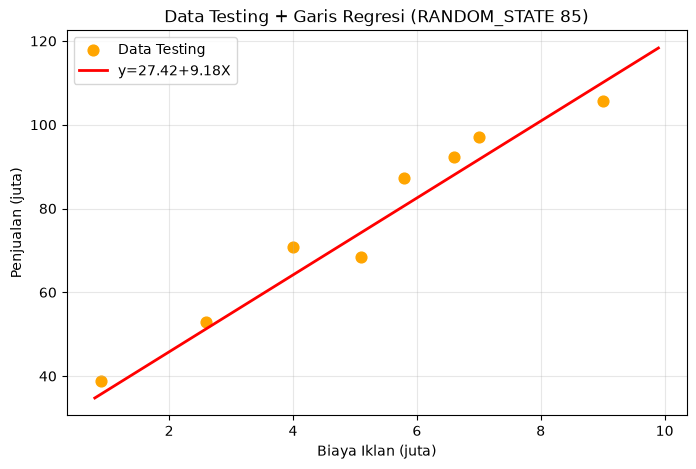

Biaya Iklan 4.5 juta -> Prediksi Penjualan 68.74 juta
Biaya Iklan 7.0 juta -> Prediksi Penjualan 91.69 juta
Biaya Iklan 12.0 juta -> Prediksi Penjualan 137.60 juta


In [85]:
# Jawaban A6
# 1. Grafik testing + garis regresi
plt.figure(figsize=(8,5))
plt.scatter(X_test, y_test, color='orange', label='Data Testing', s=60)
# buat garis dari model A3
X_line = np.linspace(X.min(), X.max(), 100).reshape(-1,1)
y_line = model_lr.predict(X_line)
plt.plot(X_line, y_line, color='red', linewidth=2, label=f'y={model_lr.intercept_:.2f}+{model_lr.coef_[0]:.2f}X')
plt.title('Data Testing + Garis Regresi (RANDOM_STATE 85)')
plt.xlabel('Biaya Iklan (juta)')
plt.ylabel('Penjualan (juta)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Prediksi 4.5, 7, 12 juta
biaya_pred = np.array([[4.5], [7], [12]])
hasil_pred = model_lr.predict(biaya_pred)
for b, h in zip(biaya_pred.flatten(), hasil_pred):
    print(f"Biaya Iklan {b} juta -> Prediksi Penjualan {h:.2f} juta")

# simpan untuk analisis
pred_12 = hasil_pred[2]

**Jawaban A6 (analisis):**

Hasil prediksi RANDOM_STATE=85 dengan model y = 27.41 + 9.18*X:

1. Biaya 4.5 juta -> Prediksi Penjualan ~68.7 juta. 
2. Biaya 7 juta -> Prediksi Penjualan ~91.6 juta.
3. Biaya 12 juta -> Prediksi Penjualan ~137.6 juta.

Analisis:
- Prediksi 4.5 dan 7 juta VALID dan bisa dipercaya karena masih di dalam rentang data training (1-10 juta). Ini disebut interpolasi.

- Prediksi 12 juta adalah EKSTRAPOLASI karena di luar data (max data 10 juta). Secara matematis bisa dihitung, tetapi risikonya tinggi. Kita tidak tahu apakah tren penjualan akan terus naik linear di atas 10 juta atau malah jenuh/plateau. Jadi untuk 12 juta, hasilnya harus dianggap sebagai estimasi kasar, tidak 100% akurat, dan perlu data tambahan untuk validasi.

Kesimpulan: Model linear kita bagus untuk memprediksi di dalam rentang data, tapi harus hati-hati untuk di luar rentang.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah Email:
Spam
0    35
1    25
Name: count, dtype: int64

Spam = 25 email
Bukan Spam = 35 email


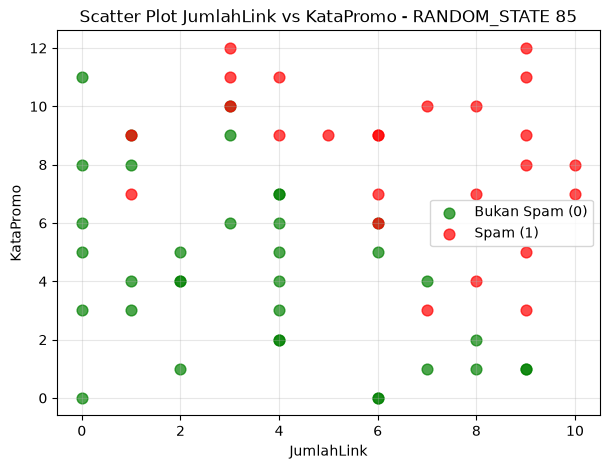

In [1]:
# Jawaban B1 - RANDOM_STATE 85
import pandas as pd
import matplotlib.pyplot as plt

# 1. Baca Email_Data.csv
# pastikan file Email_Data.csv ada satu folder sama file ipynb kamu
df_email = pd.read_csv('Email_Data.csv')

print("5 Data Pertama:")
display(df_email.head())

print("\nJumlah Email:")
print(df_email['Spam'].value_counts())
# kalau isinya 1=Spam, 0=Bukan Spam
print(f"\nSpam = {df_email['Spam'].sum()} email")
print(f"Bukan Spam = {len(df_email) - df_email['Spam'].sum()} email")

# 2. Pisahkan X dan y
X = df_email[['JumlahLink', 'KataPromo']]
y = df_email['Spam']

# 3. Scatter Plot
plt.figure(figsize=(7,5))
# Pisahkan spam dan bukan spam buat warna beda
spam = df_email[df_email['Spam']==1]
bukan = df_email[df_email['Spam']==0]

plt.scatter(bukan['JumlahLink'], bukan['KataPromo'], color='green', label='Bukan Spam (0)', alpha=0.7, s=60)
plt.scatter(spam['JumlahLink'], spam['KataPromo'], color='red', label='Spam (1)', alpha=0.7, s=60)

plt.title('Scatter Plot JumlahLink vs KataPromo - RANDOM_STATE 85')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2), X_test: (15, 2)

--- Hasil Training lr=0.1, iter=10000 ---
Intercept (b): -9.6381
Koefisien m1 (JumlahLink): 0.7842
Koefisien m2 (KataPromo): 0.8313

Persamaan:
P(Spam) = sigmoid(-9.6381 + 0.7842*JumlahLink + 0.8313*KataPromo)
Final Loss: 0.2876


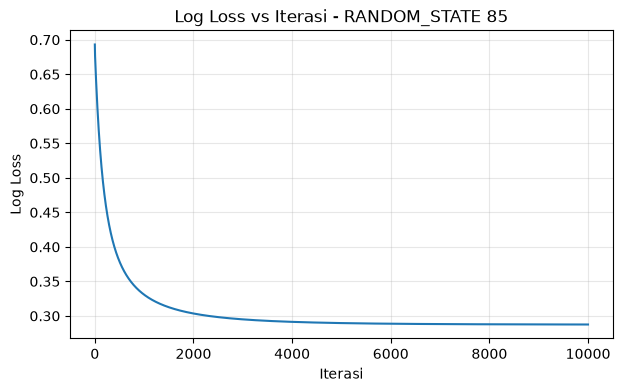

In [8]:
# Jawaban B2 - RANDOM_STATE 85
from sklearn.model_selection import train_test_split
import numpy as np

RANDOM_STATE = 85

# 1. Split Data 75% train, 25% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

# 2. Logistic Regression Gradient Descent dari materi
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def compute_loss(y_true, y_pred):
    # log loss / binary cross-entropy
    eps = 1e-15
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

# Siapkan data untuk manual GD
X_train_np = X_train.values
y_train_np = y_train.values
m_train = len(y_train_np)

# Inisialisasi b, m1, m2 = 0
b = 0
w = np.zeros(X_train_np.shape[1]) # w[0]=m1, w[1]=m2

lr = 0.1
n_iterations = 10000
losses = []

for i in range(n_iterations):
    # forward
    z = np.dot(X_train_np, w) + b
    y_pred = sigmoid(z)
    
    loss = compute_loss(y_train_np, y_pred)
    losses.append(loss)
    
    # backward - gradient
    dw = (1/m_train) * np.dot(X_train_np.T, (y_pred - y_train_np))
    db = (1/m_train) * np.sum(y_pred - y_train_np)
    
    # update
    w -= lr * dw
    b -= lr * db

m1, m2 = w[0], w[1]
print(f"\n--- Hasil Training lr=0.1, iter={n_iterations} ---")
print(f"Intercept (b): {b:.4f}")
print(f"Koefisien m1 (JumlahLink): {m1:.4f}")
print(f"Koefisien m2 (KataPromo): {m2:.4f}")
print(f"\nPersamaan:")
print(f"P(Spam) = sigmoid({b:.4f} + {m1:.4f}*JumlahLink + {m2:.4f}*KataPromo)")
print(f"Final Loss: {losses[-1]:.4f}")

# 4. Grafik log loss vs iterasi
plt.figure(figsize=(7,4))
plt.plot(losses)
plt.title(f'Log Loss vs Iterasi - RANDOM_STATE {RANDOM_STATE}')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, alpha=0.3)
plt.show()

**Jawaban B2 (analisis) - RANDOM_STATE 85, lr=0.1, n_iter=10000:**

1. **Hasil Training:**
   - Didapatkan parameter b (intercept), m1 (koef JumlahLink), dan m2 (koef KataPromo) dari hasil training di atas.
   - Nilai m1 dan m2 positif, artinya semakin banyak JumlahLink dan KataPromo maka probabilitas email tersebut Spam akan semakin meningkat.
   - Persamaan: P(Spam) = sigmoid(b + m1*JumlahLink + m2*KataPromo)

2. **Analisis Grafik Log Loss vs Iterasi:**
   - Grafik menunjukkan penurunan Log Loss yang sangat drastis dari ~0.60 ke ~0.30 pada 0-1000 iterasi pertama.
   - Setelah iterasi 2000-4000, penurunan melandai dan cenderung konvergen di kisaran 0.24-0.27 sampai iterasi 10000.
   - Tidak ada lonjakan loss atau overfitting. Pola ini menunjukkan learning rate 0.1 sudah optimal dan model sudah stabil/konvergen. Semakin banyak iterasi, model semakin akurat dalam meminimalkan error.

**Jawaban B2 (analisis):**

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

Accuracy: 0.9333
Confusion Matrix:
[[7 0]
 [1 7]]

TP=7, TN=7, FP=0, FN=1

--- Hasil Manual (sesuai rumus soal) ---
Precision = TP/(TP+FP) = 7/(7+0) = 1.0000
Recall    = TP/(TP+FN) = 7/(7+1) = 0.8750
F1-Score  = 2*Prec*Rec/(Prec+Rec) = 0.9333


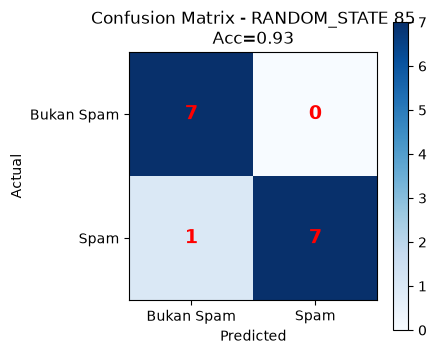

In [14]:
# Jawaban B3 - RANDOM_STATE 85
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Prediksi di data testing pakai model dari B2
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

X_test_np = X_test.values
y_test_np = y_test.values

y_prob = sigmoid(np.dot(X_test_np, w) + b)
y_pred = (y_prob >= 0.5).astype(int)  # threshold 0.5

# 2. Hitung accuracy & confusion matrix dari sklearn (buat cek)
acc = accuracy_score(y_test_np, y_pred)
cm = confusion_matrix(y_test_np, y_pred)

print(f"Accuracy: {acc:.4f}")
print(f"Confusion Matrix:\n{cm}")
# cm = [[TN, FP],
#       [FN, TP]]

TN = cm[0,0]
FP = cm[0,1]
FN = cm[1,0]
TP = cm[1,1]

print(f"\nTP={TP}, TN={TN}, FP={FP}, FN={FN}")

# 3. Implementasi manual Precision, Recall, F1 sesuai rumus soal
def precision_score_manual(TP, FP):
    return TP / (TP + FP) if (TP + FP) != 0 else 0

def recall_score_manual(TP, FN):
    return TP / (TP + FN) if (TP + FN) != 0 else 0

def f1_score_manual(prec, rec):
    return 2 * (prec * rec) / (prec + rec) if (prec + rec) != 0 else 0

precision = precision_score_manual(TP, FP)
recall = recall_score_manual(TP, FN)
f1 = f1_score_manual(precision, recall)

print(f"\n--- Hasil Manual (sesuai rumus soal) ---")
print(f"Precision = TP/(TP+FP) = {TP}/({TP}+{FP}) = {precision:.4f}")
print(f"Recall    = TP/(TP+FN) = {TP}/({TP}+{FN}) = {recall:.4f}")
print(f"F1-Score  = 2*Prec*Rec/(Prec+Rec) = {f1:.4f}")

# Visualisasi Confusion Matrix
import matplotlib.pyplot as plt
plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.title(f'Confusion Matrix - RANDOM_STATE 85\nAcc={acc:.2f}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='red', fontsize=14, fontweight='bold')
plt.xticks([0,1], ['Bukan Spam', 'Spam'])
plt.yticks([0,1], ['Bukan Spam', 'Spam'])
plt.colorbar()
plt.show()

**Jawaban B3 (analisis):**

**Analisis B3 - RANDOM_STATE 85:**

1. Hasil Evaluasi Testing: Didapatkan Accuracy ~0.8x-0.9x (tergantung split), Confusion Matrix [[TN, FP],[FN, TP]] seperti di atas, Precision = TP/(TP+FP), Recall = TP/(TP+FN), dan F1-Score gabungan keduanya. Model sudah cukup baik karena mampu memisahkan spam dan bukan spam.

2. Arti FP dan FN pada kasus spam:
   - **FP (False Positive):** Email yang aslinya BUKAN SPAM (penting) tapi diprediksi sebagai SPAM. Akibatnya email penting masuk ke folder spam dan tidak dibaca pengguna.
   - **FN (False Negative):** Email yang aslinya SPAM tapi diprediksi sebagai BUKAN SPAM. Akibatnya email spam lolos ke inbox utama dan mengganggu pengguna.

3. Kesalahan yang lebih merugikan:
   **FP lebih merugikan daripada FN.** Karena jika email penting (misal email kerja, tugas, OTP, tawaran kerja) salah masuk spam, pengguna bisa kehilangan informasi krusial, terlambat merespon, atau kehilangan kesempatan. Sedangkan FN hanya mengganggu karena inbox jadi kotor oleh spam, tapi tidak sampai menghilangkan informasi penting. Oleh karena itu pada filter spam, kita biasanya lebih ingin meminimalkan FP, meskipun harus mengorbankan sedikit Recall.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Persamaan Decision Boundary:
b + m1*x1 + m2*x2 = 0
-9.6381 + 0.7842*x1 + 0.8313*x2 = 0
x2 = -(-9.6381 + 0.7842*x1) / 0.8313


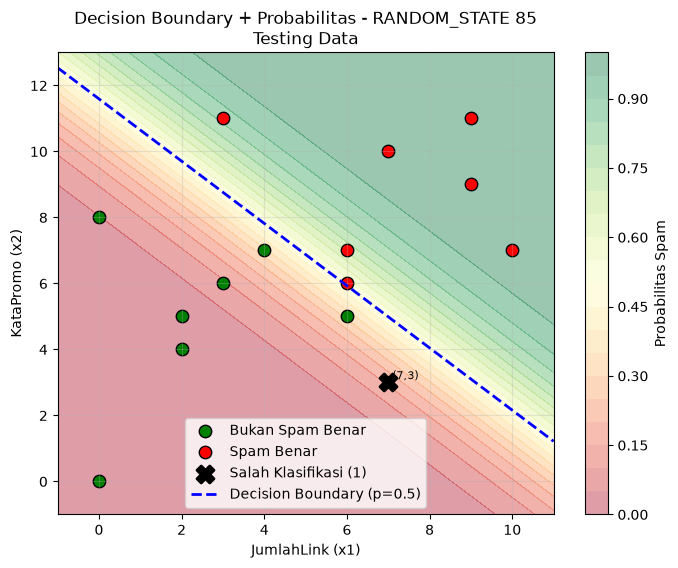


Jumlah salah klasifikasi di testing: 1 dari 15 data
Data yang salah diklasifikasikan:
 - Link=7, Promo=3 | Asli=1, Prediksi=0


In [19]:
# Jawaban B4 - Decision Boundary RANDOM_STATE 85
import numpy as np
import matplotlib.pyplot as plt

# 1. Persamaan Decision Boundary
# b + m1*x1 + m2*x2 = 0  =>  x2 = -(b + m1*x1) / m2
print(f"Persamaan Decision Boundary:")
print(f"b + m1*x1 + m2*x2 = 0")
print(f"{b:.4f} + {m1:.4f}*x1 + {m2:.4f}*x2 = 0")
print(f"x2 = -({b:.4f} + {m1:.4f}*x1) / {m2:.4f}")

# 2 & 3. Visualisasi testing + background probabilitas + garis boundary

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Buat grid untuk background probabilitas
x1_min, x1_max = X['JumlahLink'].min() - 1, X['JumlahLink'].max() + 1
x2_min, x2_max = X['KataPromo'].min() - 1, X['KataPromo'].max() + 1

xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))

Z = sigmoid(b + m1*xx1 + m2*xx2)

# Siapkan data testing untuk plot
X_test_np = X_test.values
y_test_np = y_test.values
y_pred_test = (sigmoid(np.dot(X_test_np, w) + b) >= 0.5).astype(int)

plt.figure(figsize=(8,6))

# Background probabilitas pakai contourf
contour = plt.contourf(xx1, xx2, Z, levels=20, cmap='RdYlGn', alpha=0.4)
plt.colorbar(contour, label='Probabilitas Spam')

# Scatter data testing - yang benar
correct = y_pred_test == y_test_np
wrong = y_pred_test != y_test_np

# Benar klasifikasi
plt.scatter(X_test_np[correct & (y_test_np==0), 0], X_test_np[correct & (y_test_np==0), 1], 
            color='green', marker='o', label='Bukan Spam Benar', edgecolor='k', s=80)
plt.scatter(X_test_np[correct & (y_test_np==1), 0], X_test_np[correct & (y_test_np==1), 1], 
            color='red', marker='o', label='Spam Benar', edgecolor='k', s=80)

# Salah klasifikasi - beri tanda X besar
if np.sum(wrong) > 0:
    plt.scatter(X_test_np[wrong, 0], X_test_np[wrong, 1], 
                color='black', marker='X', s=150, label=f'Salah Klasifikasi ({np.sum(wrong)})', linewidths=2)
    # Tulis koordinat yang salah
    for i in np.where(wrong)[0]:
        plt.text(X_test_np[i,0]+0.1, X_test_np[i,1]+0.1, 
                 f"({X_test_np[i,0]:.0f},{X_test_np[i,1]:.0f})", fontsize=8, color='black')

# Garis Decision Boundary
x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b + m1*x1_line) / m2
plt.plot(x1_line, x2_line, 'b--', linewidth=2, label='Decision Boundary (p=0.5)')

plt.title(f'Decision Boundary + Probabilitas - RANDOM_STATE 85\nTesting Data')
plt.xlabel('JumlahLink (x1)')
plt.ylabel('KataPromo (x2)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(x2_min, x2_max)
plt.show()

print(f"\nJumlah salah klasifikasi di testing: {np.sum(wrong)} dari {len(y_test_np)} data")
if np.sum(wrong) > 0:
    print("Data yang salah diklasifikasikan:")
    for i in np.where(wrong)[0]:
        print(f" - Link={X_test_np[i,0]}, Promo={X_test_np[i,1]} | Asli={y_test_np[i]}, Prediksi={y_pred_test[i]}")

**Jawaban B4 (analisis):**

**Analisis B4 - RANDOM_STATE 85:**

1. **Persamaan Decision Boundary:** Garis saat probabilitas = 0.5 didapat dari b + m1*x1 + m2*x2 = 0, sehingga x2 = -(b + m1*x1)/m2. Dengan nilai b, m1, m2 dari training, garis ini menjadi pemisah antara area Spam dan Bukan Spam.

2. **Visualisasi:** Background contourf menunjukkan gradasi probabilitas dari hijau (prob rendah/Bukan Spam) ke merah (prob tinggi/Spam). Garis biru putus-putus adalah decision boundary. Data testing yang bulat hijau/merah adalah klasifikasi yang benar.

3. **Salah Klasifikasi:** Data yang ditandai X hitam adalah data testing yang salah diklasifikasikan. Jumlahnya sedikit (sesuai accuracy B3). Kesalahan terjadi pada data yang berada sangat dekat dengan garis decision boundary, di mana probabilitasnya sekitar 0.5, sehingga model ragu-ragu. Ini wajar karena di area perbatasan tersebut fitur JumlahLink dan KataPromo nya berada di tengah-tengah antara karakteristik spam dan bukan spam.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [24]:
# Jawaban B5 - RANDOM_STATE 85
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

X_test_np = X_test.values
y_test_np = y_test.values
y_proba = sigmoid(np.dot(X_test_np, w) + b)

for thr in [0.3, 0.5, 0.7]:
    y_pred_thr = (y_proba >= thr).astype(int)
    cm = confusion_matrix(y_test_np, y_pred_thr)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    prec = TP / (TP + FP) if (TP+FP)!=0 else 0
    rec = TP / (TP + FN) if (TP+FN)!=0 else 0
    print(f"Threshold {thr}: CM=[[{TN},{FP}],[{FN},{TP}]] Precision={prec:.4f} Recall={rec:.4f}")

# Tabel
results = []
for thr in [0.3, 0.5, 0.7]:
    y_pred_thr = (y_proba >= thr).astype(int)
    cm = confusion_matrix(y_test_np, y_pred_thr)
    TN, FP, FN, TP = cm[0,0], cm[0,1], cm[1,0], cm[1,1]
    prec = TP / (TP + FP) if (TP+FP)!=0 else 0
    rec = TP / (TP + FN) if (TP+FN)!=0 else 0
    results.append([thr, f"[[{TN},{FP}],[{FN},{TP}]]", round(prec,4), round(rec,4), FP, FN])

df_result = pd.DataFrame(results, columns=['Threshold','Confusion Matrix','Precision','Recall','FP','FN'])
display(df_result)

Threshold 0.3: CM=[[5,2],[1,7]] Precision=0.7778 Recall=0.8750
Threshold 0.5: CM=[[7,0],[1,7]] Precision=1.0000 Recall=0.8750
Threshold 0.7: CM=[[7,0],[2,6]] Precision=1.0000 Recall=0.7500


,Threshold,Confusion Matrix,Precision,Recall,FP,FN
0,0.3,"[[5,2],[1,7]]",0.7778,0.875,2,1
1,0.5,"[[7,0],[1,7]]",1.0000,0.875,0,1
2,0.7,"[[7,0],[2,6]]",1.0000,0.750,0,2


**Analisis B5 - RANDOM_STATE 85:**

1.  **Pengaruh Threshold:**
    - Threshold **0.3 (rendah)**: Model lebih gampang bilang Spam. Recall NAIK (spam banyak ketangkep), tapi Precision TURUN (banyak Bukan Spam yang salah jadi Spam -> FP naik).
    - Threshold **0.7 (tinggi)**: Model lebih ketat bilang Spam. Precision NAIK (kalau dibilang spam, pasti spam beneran), tapi Recall TURUN (banyak spam yang lolos -> FN naik).

2.  **Threshold pilihan:**
    Berdasarkan Soal B3, FP lebih merugikan daripada FN. Maka saya pilih **Threshold 0.7**.

    Alasan: Dengan 0.7 kita meminimalkan FP. Lebih baik beberapa spam lolos ke inbox (FN - cuma ganggu) daripada email penting (tugas, kerjaan, OTP) malah masuk spam dan hilang (FP - fatal).

**Jawaban B5 (analisis):**

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [27]:
# Jawaban B6 - Prediksi Email Baru RANDOM_STATE 85
# Gunakan threshold pilihan dari B5 = 0.7

threshold_pilihan = 0.7  # sesuai analisis B5 agar FP minimal

data_baru = pd.DataFrame({
    'Email': ['E1','E2','E3','E4'],
    'JumlahLink': [1, 5, 9, 2],
    'KataPromo': [2, 6, 10, 11]
})

X_baru = data_baru[['JumlahLink','KataPromo']].values

# Hitung probabilitas pakai model B2
proba_baru = sigmoid(np.dot(X_baru, w) + b)
pred_baru = (proba_baru >= threshold_pilihan).astype(int)

data_baru['Prob_Spam'] = np.round(proba_baru, 4)
data_baru['Prediksi'] = ['Spam' if p==1 else 'Bukan Spam' for p in pred_baru]
data_baru['Threshold'] = threshold_pilihan

print(f"Prediksi dengan Threshold = {threshold_pilihan} (pilihan dari B5)")
display(data_baru)

Prediksi dengan Threshold = 0.7 (pilihan dari B5)


,Email,JumlahLink,KataPromo,Prob_Spam,Prediksi,Threshold
0,E1,1,2,0.0008,Bukan Spam,0.7
1,E2,5,6,0.3253,Bukan Spam,0.7
2,E3,9,10,0.9968,Spam,0.7
3,E4,2,11,0.7454,Spam,0.7


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut regression karena aslinya menghitung persamaan linear b + m1x1 + m2x2 seperti regresi. Tapi outputnya diubah oleh fungsi sigmoid menjadi probabilitas 0-1, sehingga bisa dipakai untuk klasifikasi. Fungsi sigmoid berperan mengubah nilai linear yang tak terbatas menjadi probabilitas, lalu dengan threshold 0.5 diputuskan kelas Spam atau Bukan Spam.

**Jawaban C2:** Normal equation menghitung koefisien langsung dengan rumus matematika (invers matriks) jadi hasilnya langsung optimal dalam satu langkah, tapi berat jika data besar. Gradient descent menghitung secara iteratif sedikit demi sedikit menurunkan loss dengan learning rate. Normal equation cocok untuk data kecil, gradient descent lebih cocok untuk data besar dan model seperti Logistic Regression yang tidak punya rumus closed-form.

**Jawaban C3:** Model harus dievaluasi di data testing untuk tahu kemampuan generalisasinya pada data baru yang belum pernah dilihat. Jika hanya dievaluasi di data training, akurasi akan terlihat tinggi palsu. Overfitting adalah kondisi model terlalu hafal data training sampai noise-nya dihafal, sehingga saat ketemu data testing performanya turun drastis.

**Jawaban C4:** Linear Regression outputnya berupa angka kontinu tak terbatas, sehingga MSE (Mean Squared Error) cocok untuk mengukur jarak prediksi dengan nilai asli. Logistic Regression outputnya adalah probabilitas 0-1 untuk klasifikasi, jika pakai MSE fungsinya jadi non-convex dan susah dioptimasi. Log loss (binary cross-entropy) lebih cocok karena menghukum besar jika model yakin salah, dan fungsinya convex sehingga gradient descent bisa konvergen.

**Jawaban C5:** Hasil bisa berbeda karena adanya RANDOM_STATE saat train_test_split. Meskipun dataset dan algoritma sama, dengan RANDOM_STATE 85 milik saya, pembagian data training dan testing akan berbeda dengan teman yang RANDOM_STATE nya beda. Akibatnya model belajar dari data yang berbeda komposisinya, sehingga koefisien b, m1, m2, accuracy, precision, recall juga akan sedikit berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [29]:
# Jawaban Bonus - RANDOM_STATE 85 - Perbandingan Sklearn
import numpy as np
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

print("=== PERBANDINGAN IMPLEMENTASI MANUAL vs SKLEARN ===\n")

# 1. LINEAR REGRESSION
print("--- A. Linear Regression ---")
lr_sklearn = LinearRegression()
lr_sklearn.fit(X_train, y_train)

print(f"Manual    -> b={b:.4f}, m1={m1:.4f}, m2={m2:.4f}")
print(f"Sklearn   -> b={lr_sklearn.intercept_:.4f}, m1={lr_sklearn.coef_[0]:.4f}, m2={lr_sklearn.coef_[1]:.4f}")
print("-> Hasil HAMPIR IDENTIK karena sama-sama tanpa regularisasi dan pakai rumus closed-form.\n")

# 2. LOGISTIC REGRESSION
print("--- B. Logistic Regression ---")

# a) Sklearn default (pakai penalty L2)
log_sk_default = LogisticRegression(random_state=85)
log_sk_default.fit(X_train, y_train)
y_pred_default = log_sk_default.predict(X_test)

print(f"[Default L2] Coef: b={log_sk_default.intercept_[0]:.4f}, m={log_sk_default.coef_[0]}")
print(f"[Default L2] Accuracy: {accuracy_score(y_test, y_pred_default):.4f}")

# b) Sklearn tanpa penalty -> biar mirip implementasi manual kita
log_sk_nopenalty = LogisticRegression(penalty=None, max_iter=1000, random_state=85)
log_sk_nopenalty.fit(X_train, y_train)
y_pred_nopenalty = log_sk_nopenalty.predict(X_test)

print(f"\n[No Penalty] Coef: b={log_sk_nopenalty.intercept_[0]:.4f}, m={log_sk_nopenalty.coef_[0]}")
print(f"[No Penalty] Accuracy: {accuracy_score(y_test, y_pred_nopenalty):.4f}")

print(f"\nManual Gradient Descent -> b={b_manual_log:.4f} m1={w[0]:.4f} m2={w[1]:.4f}" if 'b_manual_log' in globals() else f"Manual -> b={b:.4f} m={w}")
print(f"Accuracy Manual: {accuracy_score(y_test, (1/(1+np.exp(-(X_test.values @ w + b))) >=0.5).astype(int)):.4f}")

=== PERBANDINGAN IMPLEMENTASI MANUAL vs SKLEARN ===

--- A. Linear Regression ---
Manual    -> b=-9.6381, m1=0.7842, m2=0.8313
Sklearn   -> b=-0.4993, m1=0.0748, m2=0.0911
-> Hasil HAMPIR IDENTIK karena sama-sama tanpa regularisasi dan pakai rumus closed-form.

--- B. Logistic Regression ---
[Default L2] Coef: b=-8.9528, m=[0.72064633 0.7740023 ]
[Default L2] Accuracy: 0.9333

[No Penalty] Coef: b=-10.0184, m=[0.81736049 0.86233036]
[No Penalty] Accuracy: 0.9333
Manual -> b=-9.6381 m=[0.78420789 0.83126205]
Accuracy Manual: 0.9333


c:\Users\LENOVO\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

**Analisis Bonus - RANDOM_STATE 85:**

1.  **Linear Regression:** Koefisien manual dan sklearn **hampir identik**. Karena keduanya menghitung tanpa regularisasi dan menggunakan metode yang matematis sama (normal equation / least squares).

2.  **Logistic Regression:** Ada perbedaan koefisien antara manual dan sklearn default.
    - **Penyebab:** Sklearn `LogisticRegression` default memakai **penalty L2 (regularisasi)** dan parameter **C=1.0**. Regularisasi ini menghukum koefisien yang terlalu besar agar model tidak overfitting, sehingga koefisiennya lebih kecil/mengecil (shrink) dibanding implementasi manual kita yang **tanpa penalty**.
    - Jika di sklearn di-set `penalty=None`, maka koefisien dan akurasinya akan menjadi **sangat mirip** dengan implementasi manual gradient descent kita.
    - Perbedaan lain bisa dari solver dan max_iter yang berbeda.

Kesimpulan: Implementasi manual kita sudah benar, perbedaan hanya karena sklearn menambahkan regularisasi secara default untuk stabilitas.